# Default of Credit Card Clients
## ~A Machine Learning Project

---
# 0 · Setup

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix

pd.set_option("display.max_columns", 50)
RANDOM_STATE = 42

print("setup ok")

setup ok


In [3]:
path = r"C:\Users\keete\OneDrive\Desktop\dataProjects\projects\credit_card_proj\data\default_of_credit_card_clients.xls"
df = pd.read_excel(path)
df.head()

,Unnamed: 0,X1,X2,X3,X4,X5,X6,X7,X8,X9,X10,X11,X12,X13,X14,X15,X16,X17,X18,X19,X20,X21,X22,X23,Y
0,ID,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,PAY_0,PAY_2,PAY_3,PAY_4,PAY_5,PAY_6,BILL_AMT1,BILL_AMT2,BILL_AMT3,BILL_AMT4,BILL_AMT5,BILL_AMT6,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6,default payment next month
1,1,20000,2,2,1,24,2,2,-1,-1,-2,-2,3913,3102,689,0,0,0,0,689,0,0,0,0,1
2,2,120000,2,2,2,26,-1,2,0,0,0,2,2682,1725,2682,3272,3455,3261,0,1000,1000,1000,0,2000,1
3,3,90000,2,2,2,34,0,0,0,0,0,0,29239,14027,13559,14331,14948,15549,1518,1500,1000,1000,1000,5000,0
4,4,50000,2,2,1,37,0,0,0,0,0,0,46990,48233,49291,28314,28959,29547,2000,2019,1200,1100,1069,1000,0


## 1) Preprocessing - Change Column Names

In [4]:
### RUN CELL ONCE OR START OVER
# Replaces the useless column names with the more useful ones that are right below it
df.columns = df.iloc[0]

# Once replaced with useful information, we are free to delete the 0th row index
df = df.drop(0).reset_index(drop=True)
df.head()

,ID,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,PAY_0,PAY_2,PAY_3,PAY_4,PAY_5,PAY_6,BILL_AMT1,BILL_AMT2,BILL_AMT3,BILL_AMT4,BILL_AMT5,BILL_AMT6,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6,default payment next month
0,1,20000,2,2,1,24,2,2,-1,-1,-2,-2,3913,3102,689,0,0,0,0,689,0,0,0,0,1
1,2,120000,2,2,2,26,-1,2,0,0,0,2,2682,1725,2682,3272,3455,3261,0,1000,1000,1000,0,2000,1
2,3,90000,2,2,2,34,0,0,0,0,0,0,29239,14027,13559,14331,14948,15549,1518,1500,1000,1000,1000,5000,0
3,4,50000,2,2,1,37,0,0,0,0,0,0,46990,48233,49291,28314,28959,29547,2000,2019,1200,1100,1069,1000,0
4,5,50000,1,2,1,57,-1,0,-1,0,0,0,8617,5670,35835,20940,19146,19131,2000,36681,10000,9000,689,679,0


### Save Raw Data

In [5]:
# Get predictors and response in their raw state
X_raw = df.drop(columns=['default payment next month'])
y_raw = df['default payment next month']

print(X_raw.shape)
X_raw.head()

(30000, 24)


,ID,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,PAY_0,PAY_2,PAY_3,PAY_4,PAY_5,PAY_6,BILL_AMT1,BILL_AMT2,BILL_AMT3,BILL_AMT4,BILL_AMT5,BILL_AMT6,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6
0,1,20000,2,2,1,24,2,2,-1,-1,-2,-2,3913,3102,689,0,0,0,0,689,0,0,0,0
1,2,120000,2,2,2,26,-1,2,0,0,0,2,2682,1725,2682,3272,3455,3261,0,1000,1000,1000,0,2000
2,3,90000,2,2,2,34,0,0,0,0,0,0,29239,14027,13559,14331,14948,15549,1518,1500,1000,1000,1000,5000
3,4,50000,2,2,1,37,0,0,0,0,0,0,46990,48233,49291,28314,28959,29547,2000,2019,1200,1100,1069,1000
4,5,50000,1,2,1,57,-1,0,-1,0,0,0,8617,5670,35835,20940,19146,19131,2000,36681,10000,9000,689,679


**Make the target a Series, not a DataFrame.** `fetch_ucirepo` hands back `targets` as a
one-column *DataFrame*. If you pass that straight into `.fit()`, scikit-learn prints a
`DataConversionWarning` on every single fit and some metrics behave oddly. Fix it once, here.

---
# 2) EDA

### Shape of Predictors

In [6]:
# Shape, dtypes, missing values
print("rows, cols (predictors):", X_raw.shape, "\n")

print(X_raw.dtypes.value_counts(), "\n")

print("missing values per column (nonzero only):")
print(X_raw.isna().sum()[lambda s: s > 0].sort_values(ascending=False))
# No false values

rows, cols (predictors): (30000, 24) 

object    24
Name: count, dtype: int64 

missing values per column (nonzero only):
Series([], dtype: int64)


## Figures

### Figure 1 — _Feature Correlation Matrix_

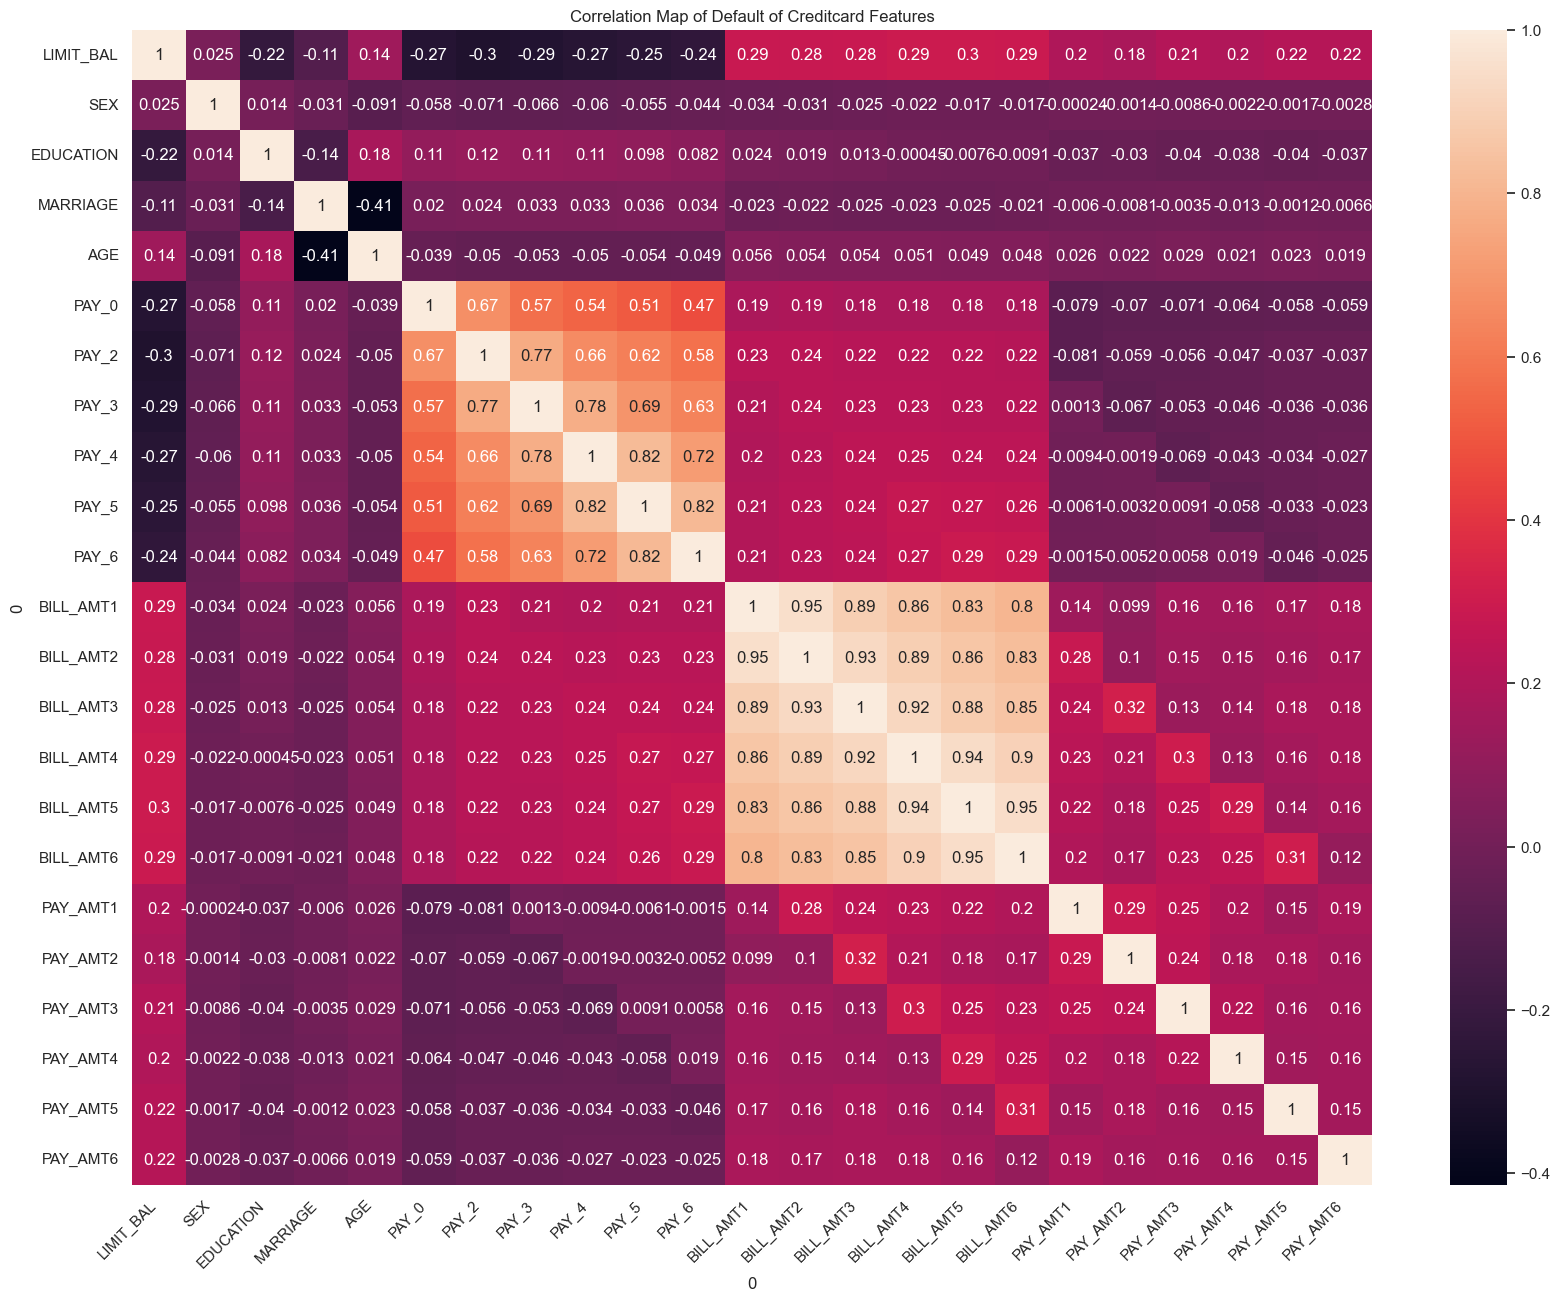

In [7]:
feature_list = [col for col in X_raw if col != 'ID']
corr_matrix = df[feature_list].corr()
plt.figure(figsize=(20,15))
sns.set_theme(font_scale=1)
sns.heatmap(corr_matrix, annot=True)
plt.xticks(rotation=45, ha='right')
plt.title("Correlation Map of Default of Creditcard Features")
plt.show()

The heatmap illustrates two unique points of discussion surrounding the multicolinearity between the Repayment (PAY_1-6) and Amount of Bill (BILL_AMT_1-6) features.

• Repayment Status: Adjacent months are more highly correlated with each other than months further apart. For example, the repayment statuses for April and May are highly correlated (0.82), while repayment status for April and September are not, by comparrison (0.47). This suggests that adjacent repayment months carry redundant/overlapping information compared to months further apart.

• Bill Amount: Like Repayment Status, Bill Amounts also decary for each proceeding month; however, the correlation coefficients are much higher. This suggests that any one Bill Amount made one month will carry redundant/overlapping information compared to any other month.

• The question of deciding which features to select for the final model is difficult for a human to decide alone, so a selection method that uses regularization (like Lasso) is ideal.

_The heatmap identified moderate-to-high correlations among Repayment Statuses and strong correlations across Bill Amounts, both of which show decaying correlations for months further apart. This indicates that these features carry redundant information, meaning that feature selection (like Lasso) should be used to avoid overfitting and over-optimistic models._

### Figure 2 - Class Distribution

<function matplotlib.pyplot.show(close=None, block=None)>

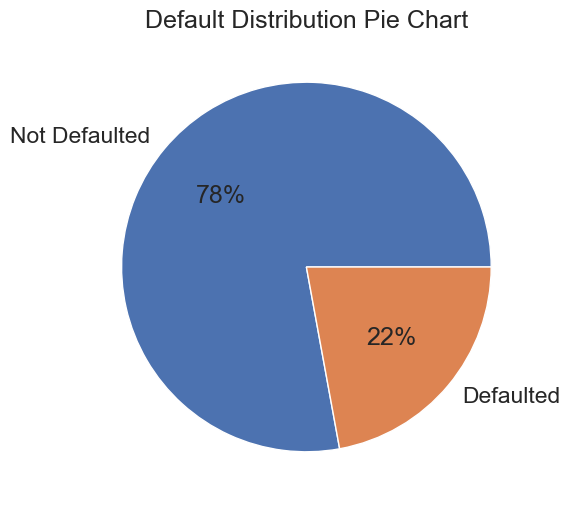

In [24]:
default_counts = df['default payment next month'].value_counts().sort_index()
labels = ['Not Defaulted', 'Defaulted']

sns.set_style('whitegrid')
sns.set_theme(font_scale=1.5)
plt.figure(figsize=(6,6))
plt.pie(default_counts, labels=labels, autopct='%.0f%%')
plt.title('Default Distribution Pie Chart')
plt.show

• The dataset has unevenly distributed classes; the majority (78%) of the dataset contains defaulted cards, while only 22% have not defaulted.

• During model evaluation, this needs to be taken into consideration. Looking at the precision, recall, and F1 scores, especially for the 'not defaulted' class can help give a clearer picture of model performance.

## Preprocessing Continued - Processing Predictors

In [9]:
X = X_raw.copy()
y = y_raw.copy()

# 1) Drop ID
X = X.drop(columns=['ID'])
# noisy variable, not needed for modeling

# 2) Rename PAY_0 to PAY_1
X.rename(columns={'PAY_0':'PAY_1'}, inplace=True)
# aligns with the naming convention of other features

# 3) Merge '0' (Unknown) in Marriage with '3' (Other)
print(X['MARRIAGE'].unique())
X['MARRIAGE'] = X['MARRIAGE'].replace({0:3})
# 0 value was not a part of dataset schema

# 4) Merge values '6' and '0' into '5'
print(X['EDUCATION'].unique())
X['EDUCATION'] = X['EDUCATION'].replace({6:4, 5:4, 0:4})
# values 5 and 6 both marked as unknowns. Doesn't make sense to have two
# 0 value also wasn't accounted for in schema, so make apart of 5 as well

# 5) Set value for female to 0 instead of 2
print(X['SEX'].unique())
X['SEX'] = X['SEX'].map({1:1, 2:0})
# Set to normal binary convention (1=male, 0=female)

[1 2 3 0]
[2 1 3 5 4 6 0]
[2 1]


---
# 3) Train/test split

In [10]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.30,
    random_state=RANDOM_STATE,
    stratify=y
)

print("train:", X_train.shape, "  test:", X_test.shape)

train: (21000, 23)   test: (9000, 23)


## Encoding

In [11]:
# Define categorical and numerical features
nominal_vars = ['SEX', 'MARRIAGE']
ordinal_vars = ['EDUCATION', 'PAY_1', 'PAY_2', 'PAY_3', 'PAY_4', 'PAY_5', 'PAY_6']
categorical_vars = nominal_vars + ordinal_vars
numerical_vars = [col for col in X if col not in categorical_vars]


### Ordinal

In [12]:
# ===== ORDINAL ENCOIDNG =====
# 1) EDUCATION
# Define education order
# Gradute > University > Highschool
education_order = {
    1: 3, #Graduate
    2: 2, #University
    3: 1, #High School
    4: 0, #Other/Unknown
}
# Create new column with correct mapping, and drop old one
X_train['EDU_CLEAN'] = X_train['EDUCATION'].map(education_order)
X_test['EDU_CLEAN'] = X_test['EDUCATION'].map(education_order)

# drop old EDUCATION column
X_train = X_train.drop(columns=['EDUCATION'])
X_test = X_test.drop(columns=['EDUCATION'])

# 2) PAYMENT 
#define repayment order
# No balance > Duly Paid > Minimum payment > 1m delay > 2m delay >...
payment_order = {
    -2: 12, #Inactive account/zero charge balance
    -1: 11, #Duly paid (on time & in full)
    0: 10, #Minimum payment paid
    1: 9, #Payment delay for one month
    2: 8, #Payment delay for two months
    3: 7, #Payment delay for three months
    4: 6, #Payment delay for four months
    5: 5, #Payment delay for five months
    6: 4, #Payment delay for six months
    7: 3, #Payment delay for seven months
    8: 2, #Payment delay for eight months
    9: 1, #Payment delay for nine months
}

pay_vars = ['PAY_1', 'PAY_2', 'PAY_3', 'PAY_4', 'PAY_5', 'PAY_6']
for count, pay in enumerate(pay_vars):
    # Creates a new column for each of the 6 pay vars
    X_train[f'PAY_{count+1}_CLEAN'] = X_train[pay].map(payment_order)
    X_test[f'PAY_{count+1}_CLEAN'] = X_test[pay].map(payment_order)
    # Drop old pay columns
    X_train = X_train.drop(columns=[pay])
    X_test = X_test.drop(columns=[pay])

#print(f"The length of columns is: {len(X.columns)}")

#print(X.head())

### Nominal

In [13]:
# 3) MARRIAGE, X_TRAIN
#initialize encoder and encode marraige
encoder = OneHotEncoder(sparse_output=False)
marriage_encoded_train = encoder.fit_transform(X_train[['MARRIAGE']])

#create an new dataframe that contains the encoded marraige
encoded_df_train = pd.DataFrame(
    marriage_encoded_train,
    columns=encoder.get_feature_names_out(['MARRIAGE']),
    index=X_train.index
)
#add encoded columns to X_train
X_train = pd.concat([encoded_df_train, X_train], axis=1).drop(columns=['MARRIAGE'])

# 3.1) MARRIAGE, X_TEST
marriage_encoded_test = encoder.transform(X_test[['MARRIAGE']])

#create encoded test df
encoded_df_test = pd.DataFrame(
    marriage_encoded_test,
    columns=encoder.get_feature_names_out(['MARRIAGE']),
    index=X_test.index
)
#add to X_test
X_test = pd.concat([encoded_df_test, X_test], axis=1).drop(columns=['MARRIAGE'])

#print(X.head(5))
#print(f"The length of columns is: {len(X.columns)}")

### Numerical

In [14]:
# ===== STANDARDIZATION =====
# Initialize scaler
scaler = StandardScaler()

# Fit & Transform the test set
X_train[numerical_vars] = scaler.fit_transform(X_train[numerical_vars])
# Fit the train set
X_test[numerical_vars] = scaler.transform(X_test[numerical_vars])

# See results of Standardization and Encoding
## Keep in mind that observations were shuffled
print(X_test.head())

       MARRIAGE_1  MARRIAGE_2  MARRIAGE_3  LIMIT_BAL  SEX       AGE  \
8941          0.0         1.0         0.0   0.481650    1 -0.590997   
17618         1.0         0.0         0.0  -0.674295    0 -0.373240   
27895         0.0         1.0         0.0  -0.520169    0 -0.699875   
16103         1.0         0.0         0.0  -1.213736    0  0.171152   
4422          1.0         0.0         0.0  -0.443106    0 -0.155483   

       BILL_AMT1  BILL_AMT2  BILL_AMT3  BILL_AMT4  BILL_AMT5  BILL_AMT6  \
8941    0.687712   0.607850   0.542940   0.098817   0.096681   0.100120   
17618  -0.628356  -0.624609  -0.635014  -0.597112  -0.599890  -0.608305   
27895   1.578328   0.511449   0.441172   0.261745   0.264070   0.217211   
16103  -0.650384  -0.650227  -0.648139  -0.633339  -0.617708  -0.614854   
4422   -0.367329  -0.328703  -0.290599  -0.241394  -0.134406  -0.017777   

       PAY_AMT1  PAY_AMT2  PAY_AMT3  PAY_AMT4  PAY_AMT5  PAY_AMT6  EDU_CLEAN  \
8941  -0.039837 -0.092403 -0.178909 -0.186

---
# 4) Modeling

Logistic regression is your only model this term, so your comparison is **within** it:
**L2 vs. L1 vs. penalty effectively off.**

Three things that will trip you up:

- **`LogisticRegression` is already regularized** — L2 with `C=1.0` by default. "Plain logistic
  regression" is *not* the unpenalized model. Use `C=1e10` to get close to unpenalized.
- **`C` runs backwards from `alpha`.** `C` is *inverse* strength: **small `C` = strong penalty**.
- **L1 needs a different solver.** `penalty="l1"` with the default `lbfgs` raises `ValueError`.
  Use `solver="liblinear"`.

In [15]:
#Convert y_train and y_test to integer
y_train = y_train.astype(int)
y_test = y_test.astype(int)

def eval_classifier(name, model):
    model.fit(X_train, y_train)
    pred = model.predict(X_test)
    coef = model[-1].coef_[0]
    return {
        "Model": name,
        "Accuracy": accuracy_score(y_test, pred),
        "Precision": precision_score(y_test, pred, zero_division=0),
        "Recall": recall_score(y_test, pred),
        "F1": f1_score(y_test, pred, zero_division=0),
        "Coefs at zero": int((np.abs(coef) < 1e-8).sum()),
    }

rows = []
rows.append(eval_classifier("L2, C=1e10 (penalty ~off)",
            make_pipeline(StandardScaler(), LogisticRegression(C=1e10, max_iter=5000))))

for c in [0.01, 0.1, 1.0, 10.0]:
    rows.append(eval_classifier(f"L2, C={c}",
                make_pipeline(StandardScaler(), LogisticRegression(C=c, max_iter=5000))))

for c in [0.01, 0.05, 0.1, 1.0]:
    rows.append(eval_classifier(f"L1, C={c}",
                make_pipeline(StandardScaler(),
                              LogisticRegression(penalty="l1", solver="liblinear",
                                                 C=c, max_iter=5000))))

results = pd.DataFrame(rows).round(4)
results

c:\Users\keete\miniconda3\Lib\site-packages\sklearn\linear_model\_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(
c:\Users\keete\miniconda3\Lib\site-packages\sklearn\linear_model\_logistic.py:1160: UserWarning: Inconsistent values: penalty=l1 with l1_ratio=0.0. penalty is deprecated. Please use l1_ratio only.
  warnings.warn(
c:\Users\keete\miniconda3\Lib\site-packages\sklearn\linear_model\_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warni

,Model,Accuracy,Precision,Recall,F1,Coefs at zero
0,"L2, C=1e10 (penalty ~off)",0.8086,0.6976,0.2376,0.3544,0
1,"L2, C=0.01",0.8083,0.7052,0.2295,0.3463,0
2,"L2, C=0.1",0.8086,0.6988,0.2366,0.3535,0
3,"L2, C=1.0",0.8086,0.6976,0.2376,0.3544,0
4,"L2, C=10.0",0.8086,0.6976,0.2376,0.3544,0
5,"L1, C=0.01",0.8079,0.7155,0.2185,0.3347,8
6,"L1, C=0.05",0.8089,0.7069,0.2325,0.3500,5
7,"L1, C=0.1",0.8084,0.7001,0.2346,0.3514,3
8,"L1, C=1.0",0.8088,0.6991,0.2381,0.3552,2


**The baseline you must beat.** A model that always predicts the majority class scores the
majority-class rate. If your accuracy is close to it, your model has learned nothing — regardless of
how good the number looks.

In [16]:
majority_rate = y_test.value_counts(normalize=True).max()
print(f"always-predict-majority accuracy = {majority_rate:.3f}")
print("any model at or below this has learned nothing useful")

always-predict-majority accuracy = 0.779
any model at or below this has learned nothing useful


---
# 5) Evaluation

## Confusion Matrix

c:\Users\keete\miniconda3\Lib\site-packages\sklearn\linear_model\_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(
c:\Users\keete\miniconda3\Lib\site-packages\sklearn\linear_model\_logistic.py:1160: UserWarning: Inconsistent values: penalty=l1 with l1_ratio=0.0. penalty is deprecated. Please use l1_ratio only.
  warnings.warn(


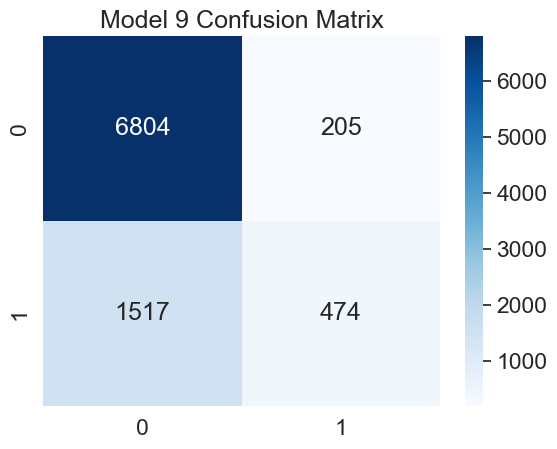

In [ ]:
best_model = make_pipeline(StandardScaler(), LogisticRegression(penalty='l1',solver='liblinear',C=1.0,max_iter=5000)).fit(X_train, y_train)
sns.heatmap(confusion_matrix(y_test, best_model.predict(X_test)), annot=True,fmt='d',cmap='Blues')
plt.title("Model 9 Confusion Matrix")
plt.show()


_From the perspective of a bank, the best model to use would be model 8. The higher recall catches more people that are likely to default which prevents the banks from handing out money to said people_